PCA(Principal Component Analysis)

Write a program to implement Principal Component Analysis (PCA) for transforming high-dimensional 
data into a lower-dimensional feature space.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
%matplotlib inline

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
data = load_breast_cancer()

In [4]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [9]:
df = pd.DataFrame(data.data, columns=data.feature_names)
print(df.head())


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [10]:
print("Original shape:", df.shape)

Original shape: (569, 30)


In [12]:
# Standard Scaler 
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)


In [13]:
print("Scaled data shape:", scaled_data.shape)

Scaled data shape: (569, 30)


In [14]:
# Apply PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

In [15]:
# Create DataFrame for PCA components
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("Reduced shape:", pca_df.shape)

Reduced shape: (569, 2)


In [16]:
# Explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:",
      round(np.sum(pca.explained_variance_ratio_) * 100, 2), "%")


Explained variance ratio: [0.44272026 0.18971182]
Total variance retained: 63.24 %


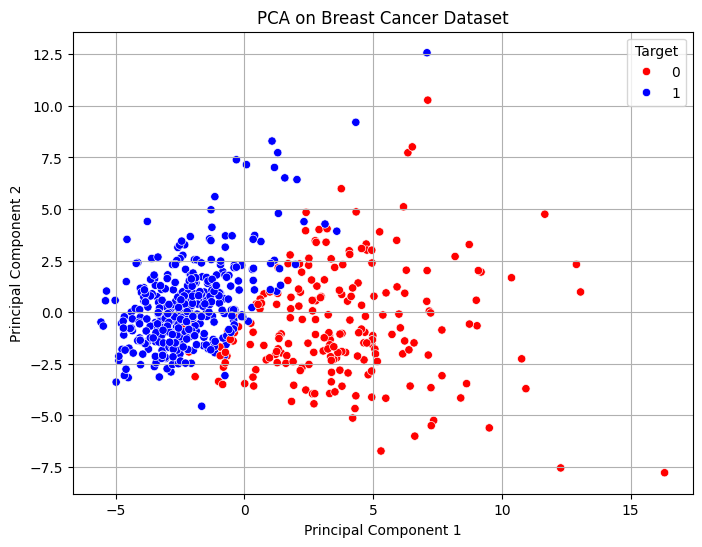

In [19]:
pca_df['Target'] = data.target

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Target',
    palette={0: 'red', 1: 'blue'}
)

plt.title("PCA on Breast Cancer Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()